In [1]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error       # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split  # 정규화 클래스
from sklearn.preprocessing import StandardScaler

In [2]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

데이터 전처리 후

In [3]:
# 훈련 데이터, 테스트 데이터 분리
train_data, test_data, train_label, test_label = train_test_split(perch_length,perch_weight)

In [7]:
# 훈련데이터는 2차원 데이터가 되어야 함.
# 훈련데이터 2차원 배영 변경
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data[:2]
test_data[:2]

array([[27.3],
       [18. ]])

In [ ]:
# 데이터 학습
lr = LinearRegression()
# 선형회귀
lr.fit(train_data,train_label)
# 데이터 예측
predict = lr.predict(test_data)
print('예측무게 : ',predict)

예측무게 :  [ 352.95475464   -1.26238337  -24.11510195  798.58276696  113.00120954
   59.67819952 -115.52597627  124.42756883  950.93422417 -165.04019986
  379.61625965  360.5723275   798.58276696  189.17693814]


In [9]:
# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train정확도 : ',score)
print('test정확도 : ',score2)


train정확도 :  0.9247220917690673
test정확도 :  0.8871417294217525


In [11]:
print(lr.coef_,lr.intercept_)

[38.0878643] -686.8439407902312


In [17]:
in_data = input('농어 길이를 입력하세요.>>')
in_data = float(in_data)
result = lr.predict([[in_data]])
print(f'농어의 예측무게 : {result[0]:.2f}g')

농어의 예측무게 : -305.97g


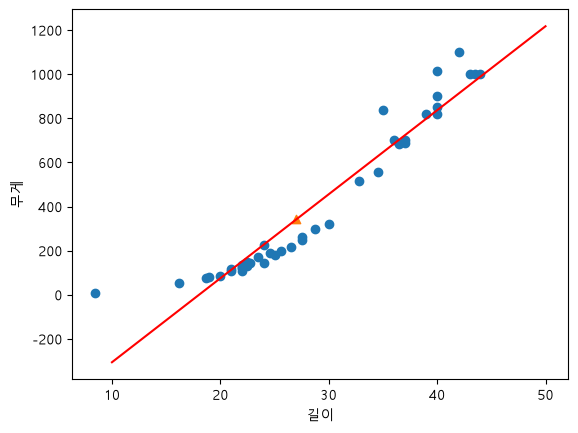

In [15]:
# 산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(27,345,marker='^')
plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_],color='r')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()